# ¿Cuándo un accidente se convierte en colapso del tráfico? Patrones de accidentes de alto impacto en EE.UU. (2016–2023)

**Curso:** Big Data — Universidad Nacional de Juliaca (UNAJ) · 2026-2

**Docente:** Mg. Leibnihtz Abrahan Ayamamani Choque

**Nombre del proyecto:** ¿Cuándo un accidente se convierte en colapso del tráfico? 

**Tema:** movilidad urbana y patrones de congestión, estudiados a través de los accidentes de tránsito que más alteran el tráfico. Con una muestra de 540 988 accidentes (2016–2023, 49 estados de EE.UU.) describimos cuándo, dónde y bajo qué condiciones se concentran, y evaluamos si los datos son confiables para orientar decisiones de control vial.


| # | Notebook | Capa | Qué hace |
|---|---|---|---|
| 1 | `01_exploration/01_eda_accidentes_eeuu.ipynb` (**este**) | Bronze | **Exploración:** fuente, pregunta, carga, perfil descriptivo y diccionario. No limpia ni evalúa reglas |
| 2 | `02_cleaning/02_silver_accidentes_eeuu.ipynb` | Bronze → Silver | Calidad en 6 dimensiones, limpieza y variables derivadas |
| 3 | `03_analysis/03_analisis_accidentes_eeuu.ipynb` | Silver → Gold | Resultados del análisis y conclusiones |

**Integrantes:**   
    - Charca Condori Yordi Brayan   
    - Chura Puma Cristian Erik   
    - Condori Quispe Kewin Erick   
    - Inofuente Trujillo David Alex   
    - Vargas Idme Vladimir Yordanov    

> **Para reproducir todos los resultados:** abrir el notebook con el kernel del entorno del proyecto (`pip install -r requirements.txt`) y ejecutar **Kernel → Restart & Run All**. Funciona desde cualquier carpeta del repositorio.
> Si el archivo `data/bronze/us_accidents/US_Accidents_March23.csv` no existe, la celda 0.3 lo descarga de Kaggle (≈ 650 MB comprimido, ≈ 3 GB descomprimido). La carga de la muestra tarda entre 1 y 3 minutos. Al final, la muestra se guarda en Bronze para que el notebook 2 no vuelva a leer los 3 GB.

---
## 0. Preparación reproducible

El notebook sigue la misma organización que el resto del repositorio `EDA` (arquitectura *medallion*):
| Capa | Carpeta | Qué contiene |
|---|---|---|
| **Bronze** | `data/bronze/us_accidents/` | El CSV original de Kaggle, **sin modificar**, y un `manifest.json` con su tamaño y huella SHA-256 |
| **Bronze (muestra)** | `data/bronze/us_accidents/muestra_7pct.csv` | La muestra fija del 7 % que usan los notebooks 2 y 3, **sin transformar** (sección 8) |
| **Outputs** | `outputs/us_accidents/` | Gráficos del notebook en PNG |

**Preparar el entorno en otra computadora** (con 3.12)
```bash
py -3.12 -m venv BigData20262
.\BigData20262\Scripts\Activate.ps1      
pip install -r requirements.txt
```
Luego abrir este notebook y elegir como kernel el Python de `BigData20262`.


In [6]:
# Celda 0.1: localizar la raíz del proyecto y definir las capas de datos
import hashlib
import importlib.util
import json
import os
import platform
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path


def find_project_root(start: Path) -> Path:
    """Localiza la raíz del repositorio por sus carpetas data/ y notebooks/."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto EDA (carpetas data/ y notebooks/).")


PROJECT_ROOT = find_project_root(Path.cwd())
BRONZE_DIR = PROJECT_ROOT / "data" / "bronze" / "us_accidents"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "us_accidents"

for folder in (BRONZE_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Proyecto : {PROJECT_ROOT}")
print(f"Python   : {sys.version.split()[0]} ({platform.system()})")
print(f"Bronze   : {BRONZE_DIR.relative_to(PROJECT_ROOT)}")
print(f"Outputs  : {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Proyecto : C:\Users\Erik\Documents\EDA-TF\EDA-bigdata
Python   : 3.12.10 (Windows)
Bronze   : data\bronze\us_accidents
Outputs  : outputs\us_accidents


In [7]:
# Celda 0.2: verificar dependencias sin modificar el entorno y registrar versiones
REQUERIDAS = ["pandas", "numpy", "matplotlib"]   # kaggle solo se exige si hay que descargar (0.3)
faltantes = [lib for lib in REQUERIDAS if importlib.util.find_spec(lib) is None]
if faltantes:
    raise ModuleNotFoundError(
        "Faltan dependencias: " + ", ".join(faltantes) +
        ". Ejecute desde la raíz del proyecto: python -m pip install -r requirements.txt"
    )

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def guardar_figura(fig, nombre: str) -> None:
    """Guarda cada gráfico en outputs/us_accidents/ para el informe."""
    fig.savefig(OUTPUT_DIR / f"{nombre}.png", dpi=120, bbox_inches="tight")


print("pandas    :", pd.__version__)
print("numpy     :", np.__version__)
print("matplotlib:", matplotlib.__version__)

pandas    : 3.1.0
numpy     : 2.5.4
matplotlib: 3.11.2


### 0.3 Obtención del dataset (capa Bronze)
La celda es **idempotente**: si el CSV ya está en Bronze no lo vuelve a descargar (salvo `FORCE_DOWNLOAD = True`). Luego registra en `manifest.json` el tamaño y la huella SHA-256 del archivo, para comprobar que todos trabajan con **el mismo archivo original**.

In [8]:
# Celda 0.3: descargar el CSV original en Bronze (solo si falta) y registrar su huella
DATASET_SLUG = "sobhanmoosavi/us-accidents"
ARCHIVO = "US_Accidents_March23.csv"
TAMANO_ESPERADO = 3_058_183_727          # bytes, según Kaggle (versión de marzo 2023)
RUTA = BRONZE_DIR / ARCHIVO
FORCE_DOWNLOAD = False

if FORCE_DOWNLOAD or not RUTA.is_file():
    kaggle_dir = Path(os.environ.get("KAGGLE_CONFIG_DIR", Path.home() / ".kaggle"))
    token_en_entorno = "KAGGLE_API_TOKEN" in os.environ or {"KAGGLE_USERNAME", "KAGGLE_KEY"} <= os.environ.keys()
    token_en_archivo = (kaggle_dir / "access_token").is_file() or (kaggle_dir / "kaggle.json").is_file()
    if not (token_en_entorno or token_en_archivo):
        raise FileNotFoundError(
            f"No se encontró {ARCHIVO} en {BRONZE_DIR.relative_to(PROJECT_ROOT)} ni un token de Kaggle en {kaggle_dir}. "
            "Configure el token (ver sección 0) o coloque el CSV manualmente en esa carpeta."
        )
    if importlib.util.find_spec("kaggle") is None:
        raise ModuleNotFoundError("Para descargar el dataset falta la librería kaggle: python -m pip install -r requirements.txt")
    print("Descargando desde Kaggle (≈ 650 MB, puede tardar varios minutos)...")
    subprocess.run([sys.executable, "-m", "kaggle", "datasets", "download",
                    "-d", DATASET_SLUG, "--unzip", "-p", str(BRONZE_DIR)], check=True)

if not RUTA.is_file():
    raise FileNotFoundError(f"La descarga no produjo el archivo esperado: {RUTA}")
if RUTA.stat().st_size != TAMANO_ESPERADO:
    print(f"⚠️ El tamaño ({RUTA.stat().st_size:,} bytes) no coincide con la versión de Kaggle "
          f"({TAMANO_ESPERADO:,} bytes): los resultados pueden diferir.")


def sha256(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


archivos = [{"name": RUTA.name, "bytes": RUTA.stat().st_size, "sha256": sha256(RUTA)}]
ruta_manifest = BRONZE_DIR / "manifest.json"
manifest = json.loads(ruta_manifest.read_text(encoding="utf-8")) if ruta_manifest.is_file() else {}
# Solo se reescribe si el archivo cambió: así la fecha de ingesta no se modifica en cada ejecución
if manifest.get("files") != archivos:
    manifest = {
        "dataset": DATASET_SLUG,
        "source_url": f"https://www.kaggle.com/datasets/{DATASET_SLUG}",
        "license": "CC BY-NC-SA 4.0",
        "ingested_at_utc": datetime.now(timezone.utc).isoformat(),
        "layer": "bronze",
        "files": archivos,
    }
    ruta_manifest.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")

print("Bronze listo (dato original, sin transformación):")
for entry in manifest["files"]:
    print(f"  {entry['name']}  {entry['bytes'] / 1024**3:.2f} GB  SHA-256 {entry['sha256'][:12]}…")

Bronze listo (dato original, sin transformación):
  US_Accidents_March23.csv  2.85 GB  SHA-256 e3e9f962e3e2…


---
## 1. Proyecto, tema e integrantes

### 1.1 Ficha del proyecto
- **Nombre del proyecto:** ¿Cuándo un accidente se convierte en colapso del tráfico?
- **Tema:** movilidad urbana y patrones de congestión, estudiados a través de los **accidentes de tránsito que más alteran el tráfico**. Con una muestra de **540 988 accidentes** (2016–2023, 49 estados de EE.UU.) describimos cuándo, dónde y bajo qué condiciones se concentran, y evaluamos si los datos son confiables para orientar decisiones de control vial.
- **¿Por qué es un caso de Big Data?** Por su **volumen** (~7,7 millones de registros y ~3 GB), su **variedad** (tiempo, ubicación, clima e infraestructura en una misma tabla) y porque combina **varias fuentes** de datos de tráfico que no registran la información de la misma forma.


### 1.2 Accidentes y tráfico (glosario)

| Término | Qué significa en este trabajo |
|---|---|
| **Severidad** (`Severity`) | Escala de 1 a 4 que mide **cuánto afecta el accidente al tráfico** (por ejemplo, cuánto retraso genera). **No** mide la gravedad de las lesiones. 1 = impacto bajo, 4 = impacto alto. |
| **Accidente de alto impacto** | En este trabajo, un accidente de **severidad 3 o 4**: es el que convierte un incidente en **colapso del tráfico**. |
| **Fuente** (`Source`) | Proveedor de datos de tráfico que reportó el accidente. Hay tres: Source1, Source2 y Source3. Cada una recoge la información a partir de departamentos de transporte, policía, cámaras y sensores. |
| **Tramo afectado** (`Distance(mi)`) | Longitud de vía afectada por el accidente. |
| **Hora local** | `Start_Time` está en la hora de la zona donde ocurrió el accidente (`Timezone`). EE.UU. tiene 4 zonas horarias continentales. |
| **Elementos de la vía** | Variables Verdadero/Falso que indican si cerca del accidente hay semáforo, cruce peatonal, rampa o salida de autopista (`Junction`), señal de pare o rotonda. Se asignan si el mapa de OpenStreetMap tiene uno a menos de 30 m del accidente (100 m para `Junction`). |

**Unidades de medida (sistema estadounidense) y su equivalencia:**

| Unidad | Equivalencia | Columna |
|---|---|---|
| milla (mi) | 1 mi ≈ 1,61 km | `Distance(mi)`, `Visibility(mi)` |
| grado Fahrenheit (°F) | °C = (°F − 32) × 5/9; 32 °F = 0 °C | `Temperature(F)` |
| pulgada (in) | 1 in = 2,54 cm | `Precipitation(in)` |
| pulgada de mercurio (inHg) | presión normal ≈ 29,9 inHg (1013 hPa) | `Pressure(in)` |
| millas por hora (mph) | 1 mph ≈ 1,61 km/h | `Wind_Speed(mph)` |

---
## 2. Pregunta motivadora y utilidad esperada

> ### ¿Cuándo, dónde y bajo qué condiciones un accidente deja de ser un incidente aislado y se convierte en un colapso del tráfico?

Cada accidente bloquea vías, retrasa ambulancias y genera congestión que afecta a miles de personas que no estuvieron involucradas. Sin embargo, los recursos de control vial suelen distribuirse de forma uniforme, sin considerar **cuándo y dónde** el riesgo es realmente mayor.

| | |
|---|---|
| **¿Qué queremos describir?** | Los patrones de hora, día, clima y tipo de vía en que se concentran los accidentes de mayor impacto en el tráfico (severidad 3–4). |
| **¿Qué decisión mejora?** | La asignación de patrullaje, semaforización y servicios de emergencia por franja horaria y zona. |
| **¿Quién se beneficia?** | Departamentos de transporte (usuario principal), policía de tránsito y servicios de emergencia. |
| **Tipo de propósito** | Mejorar una decisión. |

**Sub-preguntas que guiarán el análisis** (todas descriptivas, sin afirmar causalidad):

| # | Sub-pregunta | Variables | Dimensión |
|---|---|---|---|
| 1 | ¿En qué horas y días se concentran los accidentes de alto impacto? | `Start_Time`, `Severity` | Tiempo |
| 2 | ¿En qué estados y ciudades se concentran? | `State`, `City`, `Start_Lat`, `Start_Lng` | Lugar |
| 3 | ¿Bajo qué condiciones climáticas aumenta la proporción de alto impacto? | `Weather_Condition`, `Visibility(mi)`, `Precipitation(in)` | Clima |
| 4 | ¿Qué elementos de la vía acompañan a los accidentes de alto impacto? | `Traffic_Signal`, `Crossing`, `Junction`, `Stop`, `Roundabout` | Infraestructura |


---
## 3. Fuente, período y condiciones de uso

### 3.1 Ficha de la fuente

| Campo | Valor |
|---|---|
| Dataset | *US Accidents (2016–2023)* — Kaggle: `kaggle.com/datasets/sobhanmoosavi/us-accidents` |
| Autor / mantenedor | Sobhan Moosavi |
| Origen de los datos | APIs de tráfico que transmiten incidentes reportados por departamentos de transporte, policía, cámaras y sensores viales |
| Período | Febrero 2016 – Marzo 2023 |
| Cobertura | 49 estados de EE.UU. continental |
| Tamaño original | ~7,7 millones de registros, 46 columnas (~3 GB en CSV) |
| Archivos del dataset | Un único archivo: `US_Accidents_March23.csv` (3 058 183 727 bytes) |
| Ubicación en el proyecto | `data/bronze/us_accidents/US_Accidents_March23.csv` (descargado por la celda 0.3) |
| Fecha de la versión | 28-may-2023 (última actualización publicada en Kaggle) |
| Licencia / condiciones de uso | CC BY-NC-SA 4.0: uso no comercial, citando a los autores |
| Citas solicitadas por el autor | Moosavi et al. (2019a). *A Countrywide Traffic Accident Dataset*. arXiv:1906.05409 · Moosavi et al. (2019b). *Accident Risk Prediction based on Heterogeneous Sparse Data*. ACM SIGSPATIAL |

### 3.2 Alcance: qué se carga y por qué

| Decisión | Justificación |
|---|---|
| **Se cargan 29 de las 46 columnas** | Se eligieron las columnas de tiempo, lugar, severidad, clima y vía (las que usa la pregunta) y las necesarias para evaluar calidad (`ID`, `Source`, `End_Time`, `End_Lat`, `Weather_Timestamp`). |
| **Columnas excluidas** | Texto libre (`Description`, `Street`), columnas redundantes con otras (`County`, `Airport_Code`, `Wind_Chill(F)`, `Wind_Direction`, `Civil_Twilight`, `Nautical_Twilight`, `Astronomical_Twilight`) y elementos de la vía muy poco frecuentes (`Amenity`, `Bump`, `Give_Way`, `No_Exit`, `Railway`, `Station`, `Traffic_Calming`, `Turning_Loop`). |
| **Muestra aleatoria del 7 %** (~541 000 filas) | El archivo completo ocupa varios GB en memoria y no es manejable en una computadora personal. Un 7 % aleatorio conserva la distribución del total y sigue siendo una muestra muy grande. |
| **Lectura por bloques de 500 000 filas** | Evita cargar los 3 GB de una sola vez: se toma el 7 % de cada bloque y luego se unen. |
| **Semilla fija** (`random_state=42`) | Garantiza que cualquier persona que ejecute el notebook obtenga **exactamente la misma muestra** y los mismos resultados. |

---
## 4. Unidad de análisis

**Cada fila representa un accidente de tránsito reportado.** Contiene:
- **cuándo** ocurrió (`Start_Time`, `End_Time`),
- **dónde** (coordenadas, ciudad, estado),
- **el clima** en ese momento (temperatura, visibilidad, lluvia, viento),
- **los elementos de la vía** cercanos (semáforo, cruce, pare, etc.),
- y su **severidad (1 a 4)**, que mide el impacto del accidente en el tráfico.

| Elemento | Valor |
|---|---|
| Unidad de análisis | El accidente reportado |
| Clave (identificador único) | `ID` (su unicidad se verifica en el notebook 2) |
| Variable objetivo de la pregunta | `Severity` (alto impacto = 3 o 4) |
| Variable de control | `Source` (las fuentes podrían registrar distinto; se evalúa en el notebook 2) |


---
## 5. Carga reproducible y evidencia básica

In [9]:
# Celda 5.1: carga reproducible por bloques con una muestra aleatoria fija
COLUMNAS = ["ID","Source","Severity","Start_Time","End_Time",
            "Start_Lat","Start_Lng","End_Lat","End_Lng","Distance(mi)",
            "City","State","Zipcode","Country","Timezone",
            "Weather_Timestamp","Temperature(F)","Humidity(%)","Pressure(in)",
            "Visibility(mi)","Wind_Speed(mph)","Precipitation(in)","Weather_Condition",
            "Traffic_Signal","Crossing","Junction","Stop","Roundabout","Sunrise_Sunset"]
FRACCION, SEMILLA = 0.07, 42
TAMANO_BLOQUE = 500_000

t0 = time.perf_counter()
partes, filas_originales = [], 0
# Zipcode se lee como texto: mezcla códigos de 5 dígitos con códigos extendidos ("12345-6789")
for bloque in pd.read_csv(RUTA, usecols=COLUMNAS, dtype={"Zipcode": str}, chunksize=TAMANO_BLOQUE):
    filas_originales += len(bloque)
    partes.append(bloque.sample(frac=FRACCION, random_state=SEMILLA))
df = pd.concat(partes, ignore_index=True)

print(f"Carga completada en {time.perf_counter() - t0:.0f} s")
print(f"Filas del archivo original : {filas_originales:,}")
print(f"Filas de la muestra ({FRACCION:.0%})  : {len(df):,}")

Carga completada en 26 s
Filas del archivo original : 7,728,394
Filas de la muestra (7%)  : 540,988


In [10]:
# Celda 5.2: primeras filas
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),City,State,Zipcode,Country,Timezone,Weather_Timestamp,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition,Crossing,Junction,Roundabout,Stop,Traffic_Signal,Sunrise_Sunset
0,A-104248,Source2,2,2016-04-25 17:18:11,2016-04-25 18:18:11,33.939304,-117.218231,NaN,NaN,0.01,Moreno Valley,CA,92553,US,US/Pacific,2016-04-25 16:58:00,63.9,29.0,29.80,10.0,11.5,NaN,Clear,False,False,False,False,False,Day
1,A-199683,Source2,2,2017-01-10 09:40:16,2017-01-10 10:10:02,42.549671,-71.847313,NaN,NaN,0.01,Fitchburg,MA,01420,US,US/Eastern,2017-01-10 09:52:00,19.0,71.0,30.66,10.0,3.5,NaN,Clear,False,False,False,False,False,Day
2,A-140206,Source2,3,2016-09-02 17:27:56,2016-09-02 18:27:56,26.203491,-80.143852,NaN,NaN,0.00,Fort Lauderdale,FL,33334,US,US/Eastern,2016-09-02 17:53:00,91.0,48.0,29.99,10.0,12.7,NaN,Clear,False,False,False,False,False,Day
3,A-132821,Source2,2,2016-09-29 18:07:37,2016-09-29 18:51:28,27.440348,-82.575432,NaN,NaN,0.00,Bradenton,FL,34207-3610,US,US/Eastern,2016-09-29 18:05:00,77.0,88.0,30.02,1.5,3.5,0.08,Heavy Thunderstorms and Rain,False,False,False,False,True,Day
4,A-408710,Source2,3,2017-05-03 12:12:18,2017-05-03 12:44:00,33.901752,-118.370316,NaN,NaN,0.01,Hawthorne,CA,90250,US,US/Pacific,2017-05-03 11:53:00,72.0,61.0,29.96,10.0,8.1,NaN,Clear,False,False,False,False,False,Day


In [11]:
# Celda 5.3: dimensiones de la muestra (filas, columnas)
df.shape

(540988, 29)

In [12]:
# Celda 5.4: tipos de dato, nulos y memoria
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 540988 entries, 0 to 540987
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ID                 540988 non-null  str    
 1   Source             540988 non-null  str    
 2   Severity           540988 non-null  int64  
 3   Start_Time         540988 non-null  str    
 4   End_Time           540988 non-null  str    
 5   Start_Lat          540988 non-null  float64
 6   Start_Lng          540988 non-null  float64
 7   End_Lat            302822 non-null  float64
 8   End_Lng            302822 non-null  float64
 9   Distance(mi)       540988 non-null  float64
 10  City               540969 non-null  str    
 11  State              540988 non-null  str    
 12  Zipcode            540862 non-null  str    
 13  Country            540988 non-null  str    
 14  Timezone           540446 non-null  str    
 15  Weather_Timestamp  532555 non-null  str    
 16  Temperature(F

**Interpretación de la carga**

- La muestra contiene **540 988 accidentes y 29 columnas**, y ocupa ~414 MB en memoria (medido con `memory_usage="deep"`) frente a ~3 GB en disco.
- **Tipos que llegaron mal:** `Start_Time`, `End_Time` y `Weather_Timestamp` llegan como **texto**, no como fecha; se convierten en el notebook 2 (aquí se exploran tal como vienen). `Severity` es entera, las coordenadas y variables climáticas son decimales, y las variables de la vía son booleanas (Verdadero/Falso).
- **Columnas completas (0 nulos):** `ID`, `Source`, `Severity`, `Start_Time`, `End_Time`, `Start_Lat`, `Start_Lng`, `Distance(mi)`, `State` y los elementos de la vía. Es decir, **las variables centrales de la pregunta (cuándo, dónde, qué severidad y qué tipo de vía) están completas**.
- **Columnas con nulos** (el notebook 2 decide qué columnas se usan con la regla de máximo 3 % de nulos):

| Columna | Nulos | % |
|---|---|---|
| `End_Lat` / `End_Lng` | 238 166 | 44,02 % |
| `Precipitation(in)` | 154 617 | 28,58 % |
| `Wind_Speed(mph)` | 39 968 | 7,39 % |
| `Visibility(mi)` | 12 456 | 2,30 % |
| `Weather_Condition` | 12 232 | 2,26 % |
| `Temperature(F)` | 11 505 | 2,13 % |
| `Weather_Timestamp` | 8 433 | 1,56 % |

- **Consecuencia:** se puede describir el **cuándo y el dónde** sin pérdidas, pero el análisis por **clima** tendrá faltantes que hay que controlar.

---
## 6. Perfil descriptivo

Se describen las columnas **tal como llegan de Bronze**. Los valores extraños que aparezcan se anotan como observaciones; las reglas de calidad y sus tratamientos se aplican en el notebook 2.

### 6.1 Variables numéricas: `describe()` explicado
Además de los cuartiles, se agregan los **percentiles 1 % y 99 %**: si el máximo o el mínimo están muy lejos de ellos, hay valores extremos que revisar.

In [13]:
cols_num = ["Severity", "Start_Lat", "Start_Lng", "End_Lat", "End_Lng", "Distance(mi)",
            "Temperature(F)", "Humidity(%)", "Pressure(in)",
            "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
perfil_num = df[cols_num].describe(percentiles=[.01, .25, .5, .75, .99]).T
perfil_num["asimetria"] = df[cols_num].skew()
perfil_num.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetria
Severity,540988.0,2.21,0.49,1.00,2.00,2.00,2.00,2.00,4.00,4.00,1.82
Start_Lat,540988.0,36.21,5.07,24.56,25.73,33.41,35.83,40.09,47.47,49.00,-0.07
Start_Lng,540988.0,-94.71,17.39,-124.55,-122.97,-117.22,-87.76,-80.36,-71.49,-67.55,-0.48
End_Lat,302822.0,36.27,5.27,24.57,25.69,33.46,36.20,40.19,47.28,49.00,-0.16
End_Lng,302822.0,-95.74,18.11,-124.55,-123.20,-117.76,-88.03,-80.25,-72.88,-67.71,-0.36
Distance(mi),540988.0,0.56,1.81,0.00,0.00,0.00,0.03,0.46,7.00,333.63,26.51
Temperature(F),529483.0,61.66,19.01,-89.00,12.00,49.00,64.00,76.00,96.00,172.00,-0.51
Humidity(%),528755.0,64.85,22.81,1.00,12.00,48.00,67.00,84.00,100.00,100.00,-0.40
Pressure(in),531162.0,29.54,1.00,0.30,24.60,29.37,29.86,30.03,30.44,39.45,-3.72
Visibility(mi),528532.0,9.09,2.70,0.00,0.50,10.00,10.00,10.00,10.00,100.00,2.42


**Interpretación de las variables numéricas** (dato → significado → consecuencia)

- **Severity:** media 2,21 y mediana 2 → la mayoría de accidentes son de impacto moderado → los de alto impacto (3–4) son el grupo minoritario que interesa.
- **Start_Lat / Start_Lng:** latitudes entre 24,56 y 49,00 y longitudes entre −124,55 y −67,55 → todas caen dentro de EE.UU. continental → la ubicación es **válida**.
- **Distance(mi):** mediana de solo 0,03 millas y al menos el 25 % con distancia **0**, pero el máximo llega a **333,63 millas** → distribución muy sesgada → podría ser un valor por defecto (se revisa en el notebook 2).
- **Temperature(F):** mínimo **−89 °F** (−67 °C) y máximo **172 °F** (78 °C) → valores físicamente imposibles en EE.UU. → probables errores del sensor.
- **Pressure(in):** mínimo **0,30 inHg** y máximo **39,45 inHg**, cuando la presión normal ronda 29,9 → probables errores de registro. El percentil 1 % es **24,6** porque se trata de **presión de estación** (sin corregir al nivel del mar): en ciudades altas como Denver (~1 600 m) la presión es naturalmente menor, así que **no** es un error.
- **Wind_Speed(mph):** máximo de **243 mph** (391 km/h), más que un huracán extremo → valor atípico.
- **Visibility(mi):** los percentiles 25, 50 y 75 valen exactamente **10** → 10 millas parece ser el **valor máximo que reporta el sensor**, no una medición exacta → la visibilidad solo distingue bien los casos de visibilidad **reducida**.
- **Humidity(%):** entre 1 y 100 → rango válido.
- **Precipitation(in):** solo 386 371 valores (28,58 % nulos) y la mayoría son 0 → es la variable climática **menos confiable**.

### 6.2 Variables categóricas: ¿cuántas categorías hay y cuál domina?

In [14]:
cols_cat = ["ID", "Source", "City", "State", "Zipcode", "Country", "Timezone",
            "Weather_Condition", "Sunrise_Sunset"]
perfil_cat = pd.DataFrame({
    "no_nulos": df[cols_cat].notna().sum(),
    "categorias": df[cols_cat].nunique(),
    "mas_frecuente": [df[c].value_counts().index[0] for c in cols_cat],
    "frecuencia": [df[c].value_counts().iloc[0] for c in cols_cat],
})
perfil_cat["% del total"] = (perfil_cat["frecuencia"] / len(df) * 100).round(2)
perfil_cat

,no_nulos,categorias,mas_frecuente,frecuencia,% del total
ID,540988,540988,A-104248,1,0.00
Source,540988,3,Source1,302822,55.98
City,540969,9667,Miami,12915,2.39
State,540988,49,CA,121832,22.52
Zipcode,540862,136468,91761,787,0.15
Country,540988,1,US,540988,100.00
Timezone,540446,4,US/Eastern,250575,46.32
Weather_Condition,528756,108,Fair,179038,33.09
Sunrise_Sunset,539299,2,Day,373789,69.09


In [15]:
cols_via = ["Traffic_Signal", "Crossing", "Junction", "Stop", "Roundabout"]
(df[cols_via].mean() * 100).round(2).sort_values(ascending=False).to_frame("% de accidentes con el elemento")

,% de accidentes con el elemento
Traffic_Signal,14.77
Crossing,11.39
Junction,7.38
Stop,2.78
Roundabout,0.00


**Interpretación de las variables categóricas**

- **ID:** 540 988 valores distintos en 540 988 filas → cada accidente tiene un identificador propio.
- **Source:** 3 fuentes; `Source1` aporta 302 822 registros (56 %) → que haya fuentes distintas puede generar diferencias en cómo se registra cada accidente → se evalúa en el notebook 2.
- **State:** 49 estados; **California concentra 121 832 accidentes (22,5 %)** → fuerte concentración geográfica.
- **City:** 9 667 ciudades; Miami es la más frecuente (12 915).
- **Country:** un solo valor (US) → no aporta información.
- **Timezone:** 4 zonas horarias; la más frecuente es US/Eastern (250 575) → las horas están en **hora local**, lo que permite comparar "las 8 a. m." entre estados.
- **Weather_Condition:** **108 categorías**, con "Fair" (despejado) como la más frecuente (179 038) → muchas categorías son variantes de lo mismo ("Rain", "Light Rain", "Heavy Rain") y deberán agruparse para el análisis.
- **Sunrise_Sunset:** el 69,3 % de los accidentes con dato ocurre de día (373 789 de 539 299).
- **Elementos de la vía:** muestran qué porcentaje de accidentes ocurre cerca de cada elemento; las rotondas son muy poco frecuentes, por lo que cualquier conclusión sobre ellas tendrá poca muestra.

### 6.3 Distribución de la severidad (variable central)

Severity
1     0.87
2    79.68
3    16.79
4     2.65


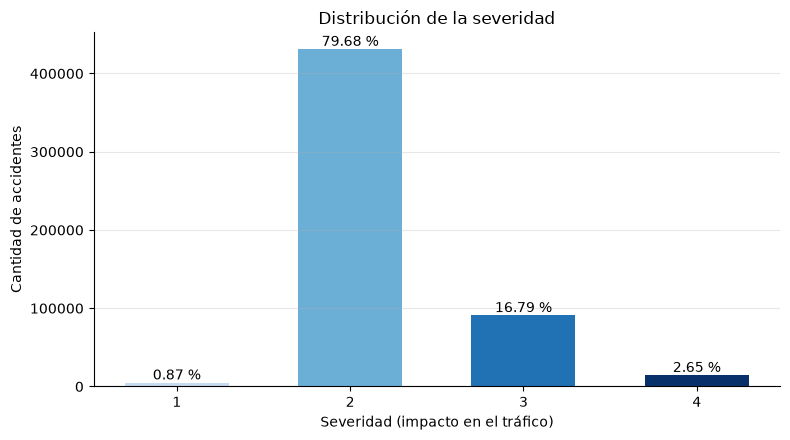

In [16]:
sev = df["Severity"].value_counts().sort_index()
sev_pct = sev / sev.sum() * 100
print(sev_pct.round(2).rename("%").to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
colores_sev = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]   # un solo tono: claro = bajo impacto, oscuro = alto
ax.bar(sev.index.astype(str), sev.values, color=colores_sev, width=0.6)
for i, (v, p) in enumerate(zip(sev.values, sev_pct.values)):
    ax.text(i, v, f"{p:.2f} %", ha="center", va="bottom")
ax.set_xlabel("Severidad (impacto en el tráfico)")
ax.set_ylabel("Cantidad de accidentes")
ax.set_title("Distribución de la severidad")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "exploracion_01_distribucion_severidad")
plt.show()

**Interpretación:** el **79,68 %** de los accidentes es de severidad 2. Los de **alto impacto (3–4) suman 19,44 %** (16,79 % + 2,65 %), unos 105 000 casos en la muestra: una minoría, pero suficientemente grande para describir sus patrones con confianza. La severidad 1 es casi inexistente (0,87 %).

### 6.4 ¿Dónde? Concentración por estado

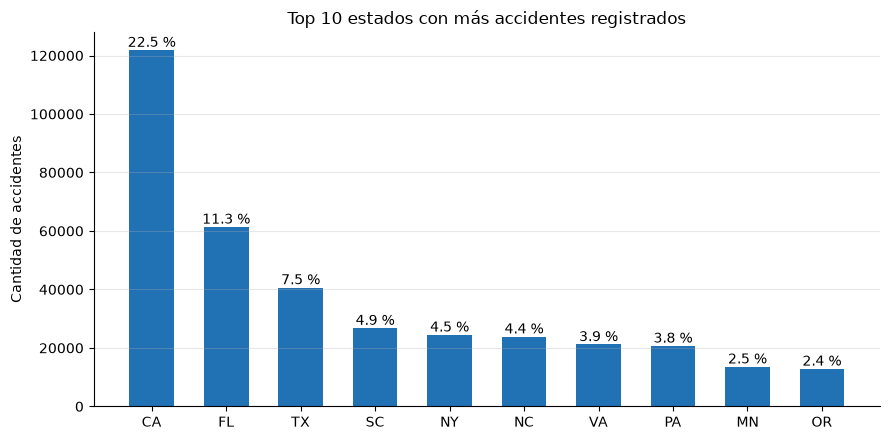

In [17]:
top_estados = df["State"].value_counts().head(10)
pct_est = top_estados / len(df) * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(top_estados.index, top_estados.values, color="#2171b5", width=0.6)
for i, (v, p) in enumerate(zip(top_estados.values, pct_est.values)):
    ax.text(i, v, f"{p:.1f} %", ha="center", va="bottom")
ax.set_ylabel("Cantidad de accidentes")
ax.set_title("Top 10 estados con más accidentes registrados")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "exploracion_02_top10_estados")
plt.show()

**Interpretación:** California concentra el **22,5 %** de los accidentes, el doble que Florida (11,3 %), seguida de Texas (7,5 %), Carolina del Sur (4,9 %) y Nueva York (4,5 %). Solo 3 estados reúnen el **41 %** de los registros. Esta concentración puede reflejar el tamaño de la población y de la red vial, pero también una **mayor cobertura de reportes** en ciertos estados → al comparar regiones hay que tener en cuenta cuánto reporta cada fuente en cada estado.

### 6.5 ¿Cuándo? Registros por año

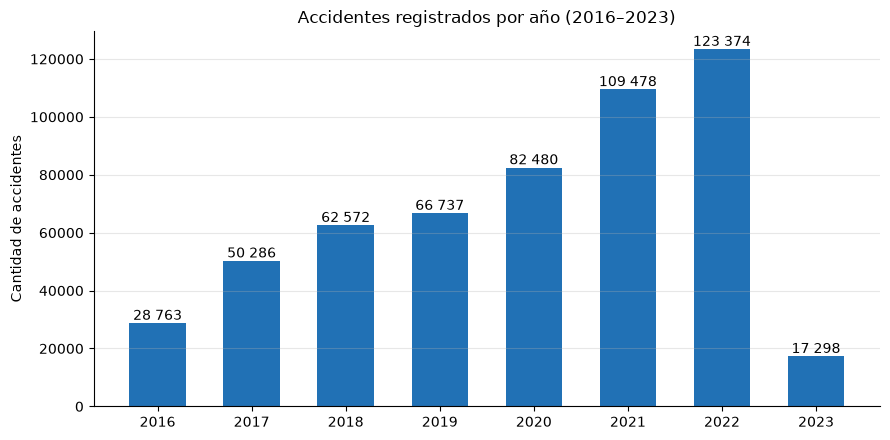

In [18]:
# El año son los 4 primeros caracteres de Start_Time (texto); la fecha se convierte recién en el notebook 2
por_anio = df["Start_Time"].str[:4].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(por_anio.index, por_anio.values, color="#2171b5", width=0.6)
for i, v in enumerate(por_anio.values):
    ax.text(i, v, f"{v:,}".replace(",", " "), ha="center", va="bottom")
ax.set_ylabel("Cantidad de accidentes")
ax.set_title("Accidentes registrados por año (2016–2023)")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "exploracion_03_accidentes_por_anio")
plt.show()

**Interpretación:** los accidentes registrados crecen cada año, de 50 286 en 2017 a **123 374 en 2022** (más del doble). El año **2023 aparece bajo (17 298) porque solo incluye enero a marzo**, y 2016 empieza en febrero, por lo que esos dos años **no son comparables** con los demás. El crecimiento puede deberse en parte a una **mayor cobertura de las fuentes** con el tiempo y no necesariamente a más accidentes reales → no debe leerse como "el tránsito empeoró".

---
## 7. Diccionario de datos

### 7.1 Catálogo técnico (automático)
Generado con código para que coincida siempre con los datos reales: tipo, nulos, valores distintos y un ejemplo tomado del propio dataset.

In [19]:
catalogo = pd.DataFrame({
    "tipo_pandas": df[COLUMNAS].dtypes.astype(str),
    "no_nulos": df[COLUMNAS].notna().sum(),
    "% nulos": (df[COLUMNAS].isna().mean() * 100).round(2),
    "valores_distintos": df[COLUMNAS].nunique(),
    "ejemplo_real": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in COLUMNAS],
})
catalogo

,tipo_pandas,no_nulos,% nulos,valores_distintos,ejemplo_real
ID,str,540988,0.00,540988,A-104248
Source,str,540988,0.00,3,Source2
Severity,int64,540988,0.00,4,2
Start_Time,str,540988,0.00,525916,2016-04-25 17:18:11
End_Time,str,540988,0.00,533773,2016-04-25 18:18:11
Start_Lat,float64,540988,0.00,395206,33.939304
Start_Lng,float64,540988,0.00,396219,-117.218231
End_Lat,float64,302822,44.02,235734,34.14825
End_Lng,float64,302822,44.02,236919,-118.08481
Distance(mi),float64,540988,0.00,10915,0.01


### 7.2 Diccionario para cualquier persona

In [20]:
diccionario = pd.DataFrame([
    ("ID", "Código del accidente", "Identificador único de cada accidente", "Identificador (texto)", "Único por registro", "Verificar duplicados (unicidad)"),
    ("Source", "Fuente", "Proveedor de datos que reportó el accidente", "Categórica nominal", "Source1, Source2, Source3", "Clave: podría medir distinto la severidad (notebook 2)"),
    ("Severity", "Severidad", "Impacto del accidente en el tráfico (no en las personas)", "Categórica ordinal", "1 (bajo) a 4 (alto)", "Define el 'colapso del tráfico' (3–4)"),
    ("Start_Time", "Inicio", "Momento en que empezó el accidente (hora local)", "Temporal", "Fecha y hora entre feb-2016 y mar-2023", "Sub-pregunta 1: hora y día"),
    ("End_Time", "Fin", "Momento en que terminó el impacto en el tráfico", "Temporal", "Posterior a Start_Time", "Mide la duración del bloqueo"),
    ("Start_Lat", "Latitud de inicio", "Latitud del punto donde ocurrió el accidente", "Numérica continua", "Grados; 24 a 50 (EE.UU. continental)", "Sub-pregunta 2: dónde"),
    ("Start_Lng", "Longitud de inicio", "Longitud del punto donde ocurrió el accidente", "Numérica continua", "Grados; −125 a −66 (EE.UU. continental)", "Sub-pregunta 2: dónde"),
    ("End_Lat", "Latitud de fin del tramo", "Latitud del punto donde termina el tramo afectado", "Numérica continua", "Grados; 24 a 50", "Extensión del impacto (solo Source1)"),
    ("End_Lng", "Longitud de fin del tramo", "Longitud del punto donde termina el tramo afectado", "Numérica continua", "Grados; −125 a −66", "Extensión del impacto (solo Source1)"),
    ("Distance(mi)", "Tramo afectado", "Longitud de vía afectada", "Numérica continua", "Millas (1 mi ≈ 1,61 km), ≥ 0", "Extensión del impacto"),
    ("City", "Ciudad", "Ciudad del accidente", "Categórica nominal", "Nombres de ciudades", "Comparar zonas"),
    ("State", "Estado", "Estado de EE.UU.", "Categórica nominal", "Código de 2 letras (49 estados)", "Comparar regiones"),
    ("Zipcode", "Código postal", "Código postal del lugar", "Categórica", "5 dígitos (a veces con extensión)", "Ubicación detallada"),
    ("Country", "País", "País del accidente", "Categórica", "Solo 'US'", "Sin aporte (valor constante)"),
    ("Timezone", "Zona horaria", "Zona horaria del lugar", "Categórica nominal", "4 zonas (US/Eastern, US/Pacific, …)", "Interpretar la hora local"),
    ("Weather_Timestamp", "Hora del clima", "Momento en que se midió el clima", "Temporal", "Cercano a Start_Time", "Comprobar que el clima corresponde al accidente"),
    ("Temperature(F)", "Temperatura", "Temperatura del aire", "Numérica continua", "°F; rango realista −40 a 130", "Contexto climático"),
    ("Humidity(%)", "Humedad", "Humedad relativa del aire", "Numérica continua", "%, 0 a 100", "Contexto climático"),
    ("Pressure(in)", "Presión", "Presión atmosférica", "Numérica continua", "inHg (presión de estación); rango realista 17 a 32", "Contexto climático"),
    ("Visibility(mi)", "Visibilidad", "Distancia a la que se ve con claridad", "Numérica continua", "Millas, ≥ 0 (tope habitual 10)", "Sub-pregunta 3: condición de riesgo"),
    ("Wind_Speed(mph)", "Viento", "Velocidad del viento", "Numérica continua", "mph; rango realista 0 a 150", "Condición de riesgo"),
    ("Precipitation(in)", "Lluvia", "Cantidad de precipitación", "Numérica continua", "Pulgadas, ≥ 0", "Sub-pregunta 3: intensidad de la lluvia"),
    ("Weather_Condition", "Clima", "Condición climática descrita en texto", "Categórica nominal", "108 categorías (Fair, Rain, Fog, Snow…)", "Sub-pregunta 3: clima y colapso"),
    ("Traffic_Signal", "Semáforo", "¿Hay semáforo cerca?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Crossing", "Cruce peatonal", "¿Hay cruce peatonal cerca?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Junction", "Rampa de autopista", "¿Hay una rampa, salida o entrada de autopista a ≤ 100 m?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Stop", "Señal de pare", "¿Hay señal de pare cerca?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Roundabout", "Rotonda", "¿Ocurrió en una rotonda?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Sunrise_Sunset", "Día / noche", "Si era de día o de noche", "Categórica binaria", "Day / Night", "Condición de luz"),
], columns=["Columna", "Nombre simple", "Descripción", "Tipo o escala", "Unidad o dominio", "Importancia para la pregunta"])

with pd.option_context("display.max_colwidth", None):
    display(diccionario)

,Columna,Nombre simple,Descripción,Tipo o escala,Unidad o dominio,Importancia para la pregunta
0,ID,Código del accidente,Identificador único de cada accidente,Identificador (texto),Único por registro,Verificar duplicados (unicidad)
1,Source,Fuente,Proveedor de datos que reportó el accidente,Categórica nominal,"Source1, Source2, Source3",Clave: podría medir distinto la severidad (notebook 2)
2,Severity,Severidad,Impacto del accidente en el tráfico (no en las personas),Categórica ordinal,1 (bajo) a 4 (alto),Define el 'colapso del tráfico' (3–4)
3,Start_Time,Inicio,Momento en que empezó el accidente (hora local),Temporal,Fecha y hora entre feb-2016 y mar-2023,Sub-pregunta 1: hora y día
4,End_Time,Fin,Momento en que terminó el impacto en el tráfico,Temporal,Posterior a Start_Time,Mide la duración del bloqueo
5,Start_Lat,Latitud de inicio,Latitud del punto donde ocurrió el accidente,Numérica continua,Grados; 24 a 50 (EE.UU. continental),Sub-pregunta 2: dónde
6,Start_Lng,Longitud de inicio,Longitud del punto donde ocurrió el accidente,Numérica continua,Grados; −125 a −66 (EE.UU. continental),Sub-pregunta 2: dónde
7,End_Lat,Latitud de fin del tramo,Latitud del punto donde termina el tramo afectado,Numérica continua,Grados; 24 a 50,Extensión del impacto (solo Source1)
8,End_Lng,Longitud de fin del tramo,Longitud del punto donde termina el tramo afectado,Numérica continua,Grados; −125 a −66,Extensión del impacto (solo Source1)
9,Distance(mi),Tramo afectado,Longitud de vía afectada,Numérica continua,"Millas (1 mi ≈ 1,61 km), ≥ 0",Extensión del impacto


> **Nota:** `Junction` no significa "intersección". Según el paper del dataset (Moosavi et al., 2019, tabla 2) es una **rampa, salida o entrada de autopista**; las intersecciones se reflejan en `Crossing`, `Stop` y `Traffic_Signal`. Las variables nuevas (alto impacto, franja horaria, clima agrupado, etc.) se crean y documentan en el notebook 2.

---
## 8. Qué dejó la exploración y qué se revisa en el notebook 2

La exploración no corrige nada: deja **observaciones** que el notebook 2 convierte en reglas de calidad.

| Observación de la exploración | Dónde se vio | Qué hace el notebook 2 |
|---|---|---|
| `End_Lat`/`End_Lng` (44 %), `Precipitation(in)` (28,6 %) y `Wind_Speed(mph)` (7,4 %) tienen muchos nulos | 5.4 `info()` | Aplica la regla de máximo 3 % de nulos para elegir columnas |
| `Distance(mi)` vale 0 en al menos el 25 % de los accidentes | 6.1 `describe()` | Mide cuántos ceros hay y decide si la columna sirve |
| Hay 3 fuentes y Source1 aporta el 56 % | 6.2 categóricas | Compara la severidad entre fuentes y entre años |
| Las fechas llegan como texto | 5.4 `info()` | Convierte las fechas y crea hora, franja, día y año |
| `Weather_Condition` tiene 108 categorías | 6.2 categóricas | Las agrupa en pocas categorías |
| 2016 y 2023 están incompletos | 6.5 registros por año | Los marca para no comparar años incompletos |
| Podría haber accidentes repetidos | — | Evalúa la unicidad (mismo inicio y misma ubicación) |

In [21]:
# Celda 8.1: guardar la muestra (sin transformar) y el diccionario en Bronze para los notebooks 2 y 3
RUTA_MUESTRA = BRONZE_DIR / "muestra_7pct.csv"
df.to_csv(RUTA_MUESTRA, index=False)
diccionario.to_csv(BRONZE_DIR / "diccionario_bronze.csv", index=False, encoding="utf-8-sig")

manifest["muestra"] = {
    "name": RUTA_MUESTRA.name, "fraccion": FRACCION, "semilla": SEMILLA, "tamano_bloque": TAMANO_BLOQUE,
    "filas_originales": filas_originales, "filas": len(df), "columnas": COLUMNAS,
}
ruta_manifest.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Muestra guardada : {RUTA_MUESTRA.relative_to(PROJECT_ROOT)}  ({RUTA_MUESTRA.stat().st_size / 1024**2:.0f} MB, {len(df):,} filas)")
print(f"Diccionario      : {(BRONZE_DIR / 'diccionario_bronze.csv').relative_to(PROJECT_ROOT)}")
print("Gráficos:")
for p in sorted(OUTPUT_DIR.glob("exploracion_*.png")):
    print(f"  {p.relative_to(PROJECT_ROOT)}")

Muestra guardada : data\bronze\us_accidents\muestra_7pct.csv  (120 MB, 540,988 filas)
Diccionario      : data\bronze\us_accidents\diccionario_bronze.csv
Gráficos:
  outputs\us_accidents\exploracion_01_distribucion_severidad.png
  outputs\us_accidents\exploracion_02_top10_estados.png
  outputs\us_accidents\exploracion_03_accidentes_por_anio.png


**Por qué se guarda la muestra:** así la muestra se selecciona **una sola vez**. El notebook 2 la lee en segundos en lugar de volver a leer los 3 GB y repetir el muestreo. Sigue siendo un dato de Bronze: son las filas originales, con sus columnas y valores sin modificar; el `manifest.json` registra la fracción, la semilla y de cuántas filas salió.